1. IMPORT LIBRARY

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from prophet import Prophet

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

2. LOAD DATASET

In [6]:
file_path = "dataset/data_clean_ok.xlsx"

df = pd.read_excel(
    file_path,
    sheet_name="aqua_600ml"
)

df.head()

,ds,y
0,2023-01-01,35
1,2023-01-02,13
2,2023-01-03,8
3,2023-01-04,8
4,2023-01-05,13


3. PREPRCESSING DATA

In [7]:
#Konversi Tanggal
df['ds'] = pd.to_datetime(df['ds'])

In [8]:
#urutkan data
df = df.sort_values('ds')

In [9]:
#cek missing value
df = df.sort_values('ds')
df = df.dropna()

In [10]:
#cek data duplikat
df.duplicated().sum()

0

In [11]:
#statistik deskriptif
df['y'].describe()

count    1092.000000
mean       16.623626
std         9.628399
min         0.000000
25%        11.000000
50%        14.000000
75%        20.000000
max        67.000000
Name: y, dtype: float64

In [12]:
#jumlah data 0
print(
    "Jumlah data 0:",
    (df['y'] == 0).sum()
)

Jumlah data 0: 5


4. VISUALISASI PENJUALAN

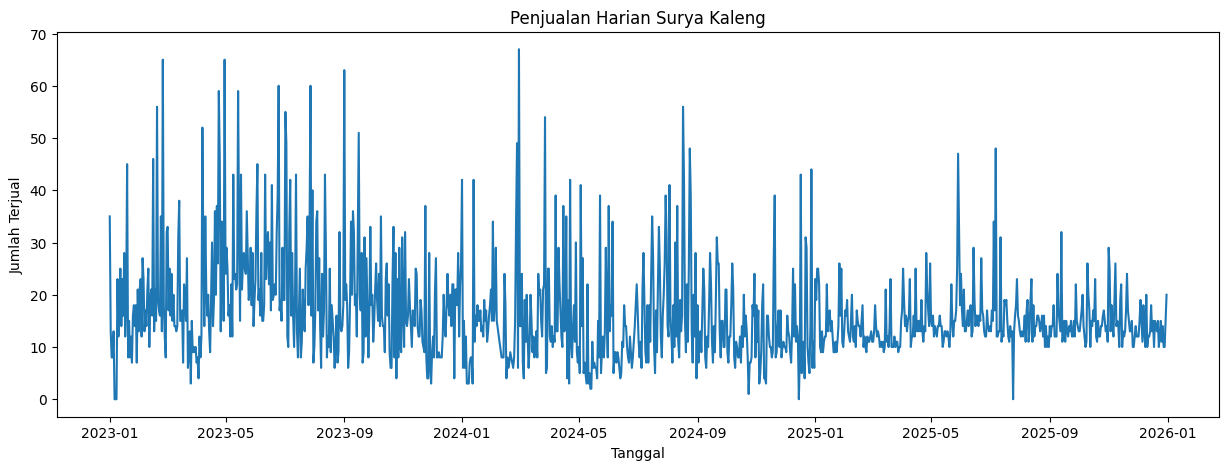

In [13]:
plt.figure(figsize=(15,5))

plt.plot(
    df['ds'],
    df['y']
)

plt.title("Penjualan Harian Surya Kaleng")
plt.xlabel("Tanggal")
plt.ylabel("Jumlah Terjual")

plt.show()

5. ANALISIS PERTAHUN

In [14]:
df['tahun'] = df['ds'].dt.year

df.groupby('tahun')['y'].mean()

tahun
2023    20.128767
2024    14.883978
2025    14.843836
Name: y, dtype: float64

6. SPLIT DATA

In [15]:
train = df[
    df['ds'] < '2025-07-01'
]

test = df[
    df['ds'] >= '2025-07-01'
]

print("Train :", len(train))
print("Test :", len(test))

Train : 908
Test : 184


7. MEMBANGUN MODEL PROPHET

In [16]:
model = Prophet(
    changepoint_prior_scale=0.01,
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False
)

model.fit(train)

14:08:17 - cmdstanpy - INFO - Chain [1] start processing
14:08:18 - cmdstanpy - INFO - Chain [1] done processing


8. PREDIKSI DATA TEST

In [17]:
future = model.make_future_dataframe(
    periods=len(test),
    freq='D'
)

forecast = model.predict(future)

In [18]:
#AMBIL PREDIKISI DATA TEST
pred_test = forecast[
    ['ds','yhat']
]

pred_test = pred_test[
    pred_test['ds'].isin(
        test['ds']
    )
]

9. EVALUASI MODEL

In [19]:
evaluation = test.merge(
    pred_test,
    on='ds'
)

In [20]:
mae = mean_absolute_error(
    evaluation['y'],
    evaluation['yhat']
)

rmse = np.sqrt(
    mean_squared_error(
        evaluation['y'],
        evaluation['yhat']
    )
)

mape = np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100

print("MAE :", round(mae))
print("RMSE :", round(rmse))
print("MAPE :", round(mape,2), "%")

NameError: name 'y_true' is not defined

10. VISUALISASI AKTUAL VS PREDIKSI

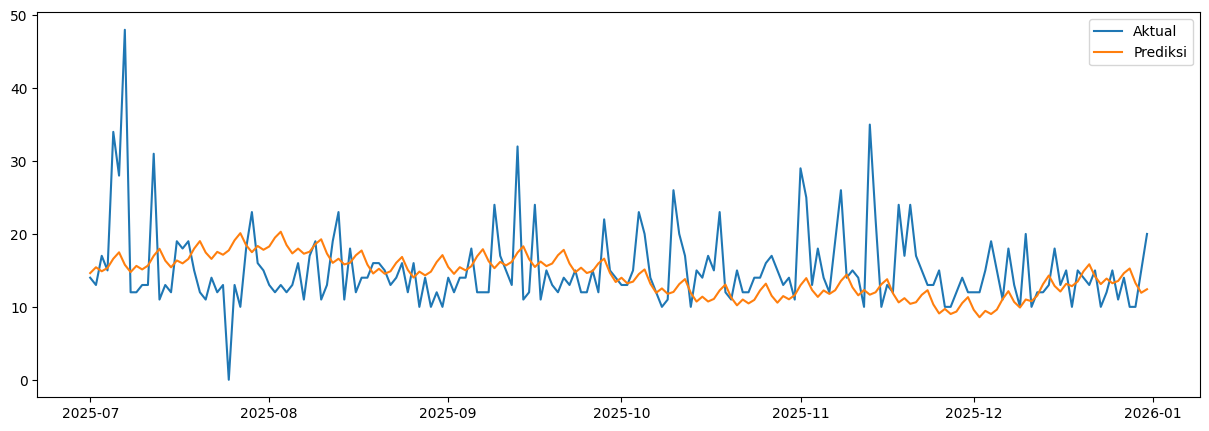

In [ ]:
plt.figure(figsize=(15,5))

plt.plot(
    evaluation['ds'],
    evaluation['y'],
    label='Aktual'
)

plt.plot(
    evaluation['ds'],
    evaluation['yhat'],
    label='Prediksi'
)

plt.legend()

plt.show()

11. ANALISIS EROR TERBESAR

In [ ]:
evaluation['error'] = abs(
    evaluation['y'] -
    evaluation['yhat']
)

evaluation.sort_values(
    'error',
    ascending=False
).head(20)

,ds,y,tahun,yhat,error
6,2025-07-07,48,2025,15.773263,32.226737
135,2025-11-13,35,2025,11.669550,23.330450
24,2025-07-25,0,2025,17.747978,17.747978
4,2025-07-05,34,2025,16.599381,17.400619
123,2025-11-01,29,2025,12.967618,16.032382
74,2025-09-13,32,2025,17.443119,14.556881
11,2025-07-12,31,2025,16.999030,14.000970
101,2025-10-10,26,2025,12.045965,13.954035
142,2025-11-20,24,2025,10.414311,13.585689
140,2025-11-18,24,2025,10.610949,13.389051


12. TRAINING FINAL MENGGUNAKAN SELURUH DATA

In [ ]:
final_model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=True
)

final_model.fit(df[['ds','y']])

10:05:04 - cmdstanpy - INFO - Chain [1] start processing
10:05:04 - cmdstanpy - INFO - Chain [1] done processing


13. PERAMALAN 14 HARI KEDEPAN

In [ ]:
future = final_model.make_future_dataframe(
    periods=14,
    freq='D'
)

forecast = final_model.predict(
    future
)

In [ ]:
forecast_14 = forecast[
    ['ds','yhat']
].tail(14)

forecast_14

,ds,yhat
1092,2026-01-01,12.250491
1093,2026-01-02,12.303367
1094,2026-01-03,13.519119
1095,2026-01-04,13.458014
1096,2026-01-05,11.717189
1097,2026-01-06,10.703660
1098,2026-01-07,10.916881
1099,2026-01-08,10.303512
1100,2026-01-09,10.448998
1101,2026-01-10,11.795585


14. HITUNG REKOMENDASI PEMBELIAN

In [ ]:
total_forecast = round(
    forecast_14['yhat'].sum()
)

print(
    "Kebutuhan stok 14 hari:",
    total_forecast
)

Kebutuhan stok 14 hari: 159


In [ ]:
#TAMBAH SAFETY STOK 10%
stok_beli = round(
    total_forecast * 1.10
)

print(
    "Rekomendasi pembelian:",
    stok_beli
)

Rekomendasi pembelian: 175
